In [9]:
import numpy as np
import matplotlib.pyplot as plt

import os
import re

from pathlib import Path
from quantify_core.data.handling import (
    locate_experiment_container,
    load_dataset,
    set_datadir,
    default_datadir,
)

In [6]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [3]:
tuid = "20250717-151633-825-3d4509"
dataset = load_dataset(tuid=tuid)
dataset

<xarray.Dataset> Size: 400kB
Dimensions:  (dim_0: 10000)
Coordinates:
    x0       (dim_0) float64 80kB 6.996e+09 6.996e+09 ... 6.997e+09 6.996e+09
    x1       (dim_0) float64 80kB 0.006103 0.00117 ... 0.002844 0.009541
    x2       (dim_0) float64 80kB 2.68e-07 1.68e-07 3.28e-07 ... 5.2e-08 5.2e-08
Dimensions without coordinates: dim_0
Data variables:
    y0       (dim_0) float64 80kB 0.9822 0.9753 0.9825 ... 0.9789 0.9771 0.9811
    y1       (dim_0) float64 80kB 0.9357 0.9469 0.933 ... 0.9392 0.9434 0.9476
Attributes:
    tuid:                             20250717-151633-825-3d4509
    name:                             Test
    grid_2d:                          False
    grid_2d_uniformly_spaced:         False
    1d_2_settables_uniformly_spaced:  True

In [4]:
F_ass = dataset.y0.data
QND_pi = dataset.y1.data

frequency = dataset.x0.data
amplitude = dataset.x1.data
duration = dataset.x2.data

print(np.max(frequency)-np.min(frequency))

5.91278076171875e-05


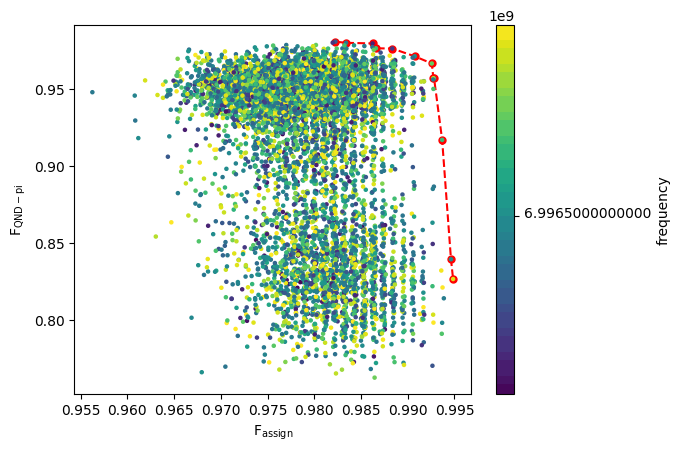

In [5]:
front_dir = "data_Pareto/20250717-161833-896547-NSGAII-Pareto data.npz"

pareto_data = np.load(front_dir)

pareto_front = pareto_data["F"]
pareto_F_ass_obj = pareto_front[:,0]
pareto_QND_pi_obj = pareto_front[:,1]

pareto_F_ass = 1-np.exp(pareto_F_ass_obj)
pareto_QND_pi = 1-np.exp(pareto_QND_pi_obj)

sort_ind = np.argsort(pareto_F_ass)
pareto_F_ass = pareto_F_ass[sort_ind]
pareto_QND_pi = pareto_QND_pi[sort_ind]

# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=frequency, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("frequency")
plt.show()


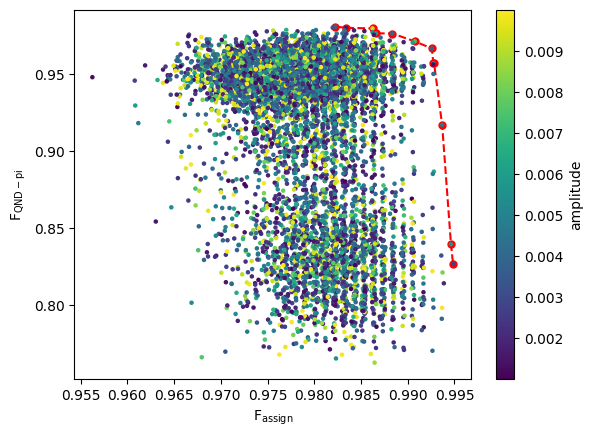

In [6]:
# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=amplitude, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("amplitude")
plt.show()

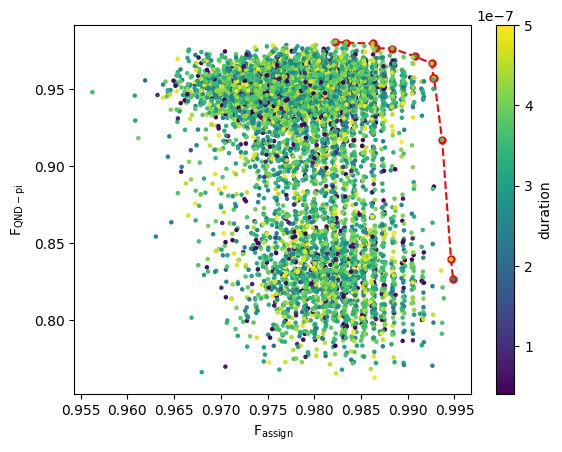

In [7]:
# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=duration, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("duration")
plt.show()

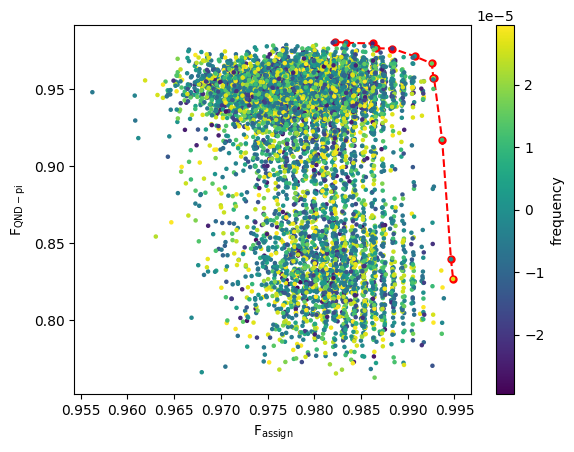

In [8]:
frequency = frequency-6.9965*1e9

# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=frequency, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("frequency")
plt.show()

In [3]:
# tuid = "20250731-110604-272-ed84d5"
tuid = "20250801-165700-837-2202ef"

dataset = load_dataset(tuid)
dataset

<xarray.Dataset> Size: 408kB
Dimensions:  (dim_0: 10201)
Coordinates:
    x0       (dim_0) float64 82kB 7.179e+09 7.162e+09 7.155e+09 ... 0.0 0.0 0.0
    x1       (dim_0) float64 82kB 0.01428 0.01137 0.008864 ... 0.0 0.0 0.0
    x2       (dim_0) float64 82kB 4.4e-07 1.32e-07 1.52e-07 ... 0.0 0.0 0.0
Dimensions without coordinates: dim_0
Data variables:
    y0       (dim_0) float64 82kB -5.315 -4.028 -4.618 -4.985 ... nan nan nan
    y1       (dim_0) float64 82kB -3.424 -3.611 -3.179 -3.836 ... nan nan nan
Attributes:
    tuid:                             20250801-165700-837-2202ef
    name:                             Pareto front q0
    grid_2d:                          False
    grid_2d_uniformly_spaced:         False
    1d_2_settables_uniformly_spaced:  True

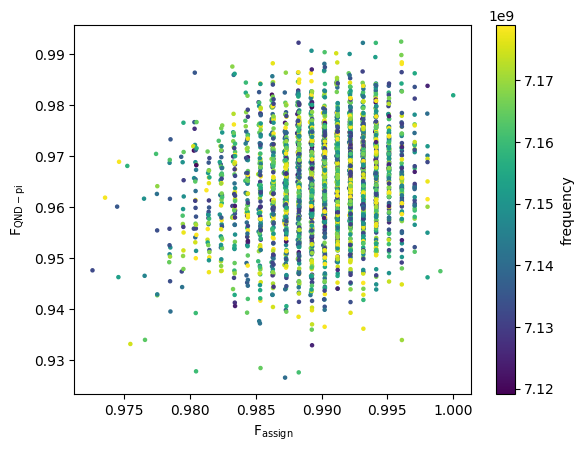

In [11]:
frequency = dataset.x0.data
amplitude = dataset.x1.data
duration = dataset.x2.data

assignfid = 1-np.exp(dataset.y0.data)
QNDpifid = 1-np.exp(dataset.y1.data)

sc = plt.scatter(assignfid, QNDpifid, c=frequency, s=5, cmap="viridis")

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("frequency")
plt.show()


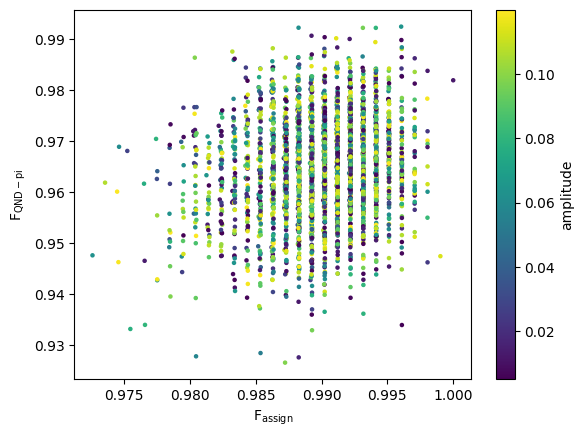

In [12]:
sc = plt.scatter(assignfid, QNDpifid, c=amplitude, s=5, cmap="viridis")

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("amplitude")
plt.show()

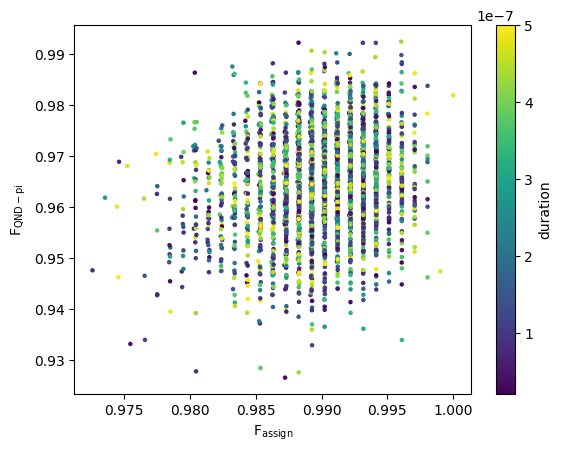

In [13]:
sc = plt.scatter(assignfid, QNDpifid, c=duration, s=5, cmap="viridis")

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("duration")
plt.show()

In [23]:
# Mask NaNs and get index of max
valid_idx = np.where(~np.isnan(QNDpifid))[0]
max_idx = valid_idx[np.argmax(QNDpifid[valid_idx])]

print(max_idx)

print(QNDpifid[max_idx])
print(assignfid[max_idx])

print(f"Frequency: {frequency[max_idx]}, \nAmplitude: {amplitude[max_idx]},\nDuration: {duration[max_idx]} ")

325
0.9924106053209667
0.9960472470238095
Frequency: 7164805776.572788, 
Amplitude: 0.06433093061334653,
Duration: 4.28e-07 


In [4]:
def get_latest_pareto_file(folder):
    # Regular expression to match filenames with timestamp at the beginning
    pattern = re.compile(r"^(\d{8}-\d{6})-.*-Pareto data\.npz$")

    latest_time = None
    latest_file = None

    for filename in os.listdir(folder):
        match = pattern.match(filename)
        if match:
            timestamp_str = match.group(1)
            try:
                # Convert string to datetime object for easy comparison
                from datetime import datetime

                timestamp = datetime.strptime(timestamp_str, "%Y%m%d-%H%M%S")
                if latest_time is None or timestamp > latest_time:
                    latest_time = timestamp
                    latest_file = filename
            except ValueError:
                continue  # Skip if timestamp parsing fails

    if latest_file:
        return os.path.join(folder, latest_file)
    else:
        return None

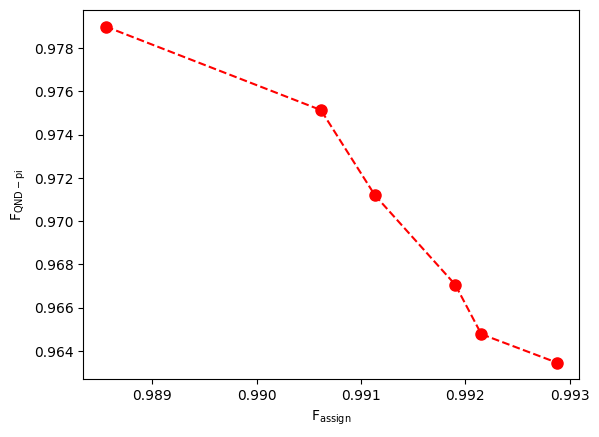

In [25]:
tuid =  "20250807-143814-354-5fadde" #"20250807-142501-183-418c2f"
dataset = load_dataset(tuid)

F_ass = 1-np.exp(dataset.y0.data)
QND_pi = 1-np.exp(dataset.y1.data)

frequency = dataset.x0.data
amplitude = dataset.x1.data
duration = dataset.x2.data

pareto_path = get_latest_pareto_file(Path(locate_experiment_container(tuid)))

pareto_data = np.load(pareto_path)

pareto_front = pareto_data["F"]
pareto_F_ass_obj = pareto_front[:, 0]
pareto_QND_pi_obj = pareto_front[:, 1]

pareto_F_ass = 1 - np.exp(pareto_F_ass_obj)
pareto_QND_pi = 1 - np.exp(pareto_QND_pi_obj)

sort_ind = np.argsort(pareto_F_ass)
pareto_F_ass = pareto_F_ass[sort_ind]
pareto_QND_pi = pareto_QND_pi[sort_ind]

plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=8, c="red")
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")
plt.show()

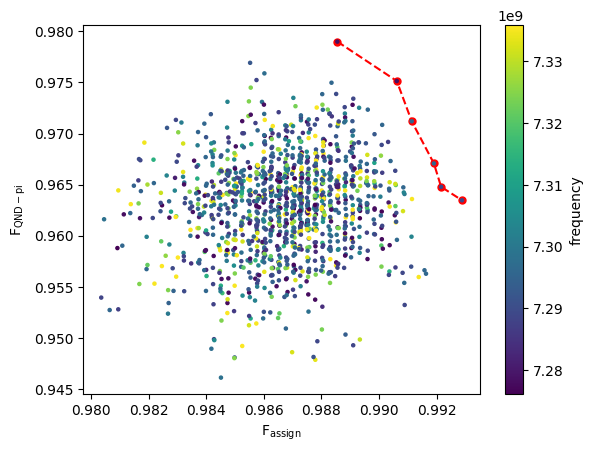

In [26]:
# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=frequency, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("frequency")
plt.show()

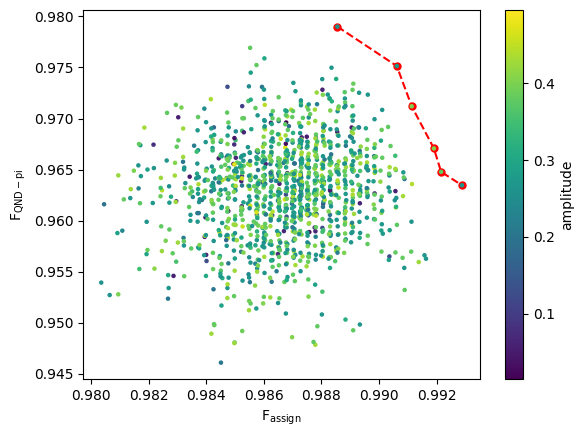

In [27]:
# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=amplitude, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("amplitude")
plt.show()

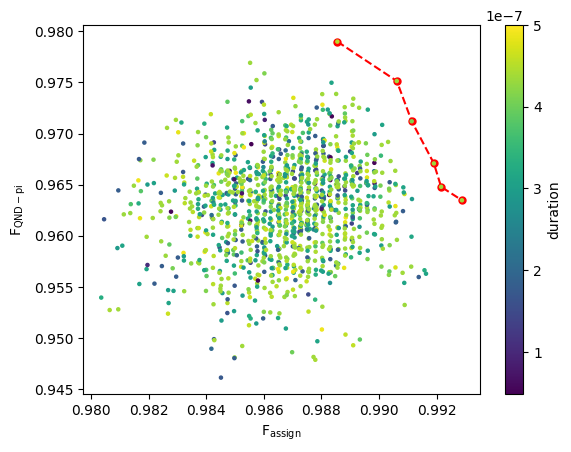

In [28]:
# Create scatter plot and store the mappable object
sc = plt.scatter(F_ass, QND_pi, c=duration, s=5, cmap="viridis", zorder=2)

# Line plot
plt.plot(pareto_F_ass, pareto_QND_pi, marker="o", ls="--", ms=5, c="red", zorder=1)

# Axes labels
plt.xlabel(r"F$_\mathrm{assign}$")
plt.ylabel(r"F$_\mathrm{QND-pi}$")

# Create colorbar FROM the scatter (this is critical)
cbar = plt.colorbar(sc)
cbar.set_label("duration")
plt.show()